## Hawker Centre Inspection: Extension 2 (Selective Visiting)

Let node $1$ be the depot and nodes $2,\ldots,n$ be the hawker centres. The vectors $y$ and $w$ include the depot.

- $x_{ij}=1$ if the team travels directly from node $i$ to node $j$.
- $y_i=1$ if node $i$ is visited.
- $w_i$ is the number of stalls at node $i$, with $w_1=0$ (no stalls at depot).
- $c_{ij}$ is the travel time from node $i$ to node $j$.
- $t_i$ is the inspection time at node $i$, with $t_1=0$ (no inspection needed at depot).
- $T$ is the total available time.
- $u_i$ is an ordering variable. If node $i$ is not visited, $u_i=0$. Otherwise, $u_i$ as an indication of the number of nodes visited prior to visiting node $i$.

The objective is to maximise the total number of stalls visited:

$$
\max \quad \sum_{i=1}^{n} w_i y_i
$$

subject to:

**Visit and route-linking constraints**

$$
\sum_{i=1}^{n} x_{ij} = y_j
\quad \forall j=1,\ldots,n
$$

$$
\sum_{j=1}^{n} x_{ij} = y_i
\quad \forall i=1,\ldots,n
$$

$$
y_1=1,
\qquad
x_{ii}=0 \quad \forall i=1,\ldots,n
$$

**Time limit**

$$
\sum_{i=1}^{n}\sum_{j=1}^{n} c_{ij}x_{ij}
+\sum_{i=1}^{n} t_i y_i
\le T
$$

**MTZ subtour-elimination constraints**

$$
u_i+1-u_j \le M(1-x_{ij})
\quad \forall i\ne j,\quad j=2,\ldots,n
$$

$$
u_1=0,
\qquad
y_i \le u_i \le (n-1)y_i
\quad i=2,\ldots,n
$$

**Variable domains**

$$
x_{ij}\in\{0,1\}
\quad \forall i,j=1,\ldots,n,
\qquad
y_i\in\{0,1\}
\quad i=1,\ldots,n
$$

We enforce $x_{ii}=0$ to prevent travelling from one node to itself. Note that $M$ is a large positive number - taking $M=n-1$ would suffice.

The formulation above requires one departure from and one return to the depot. If no tour visiting at least one hawker centre fits within $T$, the problem is infeasible.

### Imports

In [1]:
from gurobipy import *
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

### Load Data

In [2]:
DATA_PATH = os.path.join("..", "data", "processed")
nodes_df = pd.read_csv(os.path.join(DATA_PATH, "nodes.csv"))
travel_times_df = pd.read_csv(os.path.join(DATA_PATH, "time_matrix_min.csv"))

In [3]:
nodes_df

,node_id,type,name,short_name,address,postal_code,lat,lon,status,cooked_food_stalls,osrm_snap_m
0,0,depot,DEPOT - West Coast-Jurong West Town Council (B...,Depot - Town Council (Boon Lay),"325 Boon Lay Place, Singapore 649886",649886,1.345434,103.714106,Depot,0,10.0
1,1,hawker,Jurong West Hawker Centre,Jurong West Hawker Centre,"Blk 50, Jurong West St 61, Singapore 648202",648202,1.341264,103.697242,Existing (new),39,17.3
2,2,hawker,Boon Lay Place Blk 221A/B (Boon Lay Place Mark...,Boon Lay Place Market and Food Village,"Blk 221A/B, Boon Lay Place, Singapore 641221/6...",641221,1.345224,103.712801,Existing,72,30.5
3,3,hawker,Jurong West Street 52 Blk 505,Jurong West Street 52 Blk 505,"Blk 505, Jurong West Street 52, Singapore 640505",640505,1.349657,103.718444,Existing,60,38.1
4,4,hawker,Taman Jurong Market and Food Centre,Taman Jurong Market and Food Centre,"3, Yung Sheng Road, Singapore 618499",618499,1.334721,103.721584,Existing,122,28.9
5,5,hawker,Teban Gardens Road Blk 37A (Teban Gardens Mark...,Teban Gardens Market and Food Centre,"Blk 37A, Teban Garden Road, Singapore 601037",601037,1.320831,103.742748,Existing,28,47.0
6,6,hawker,West Coast Drive Blk 503 (Ayer Rajah Food Centre),Ayer Rajah Food Centre,"Blk 503, West Coast Drive, Singapore 120503",120503,1.311803,103.759751,Existing,80,26.7
7,7,hawker,Clementi West Street 2 Blk 726,Clementi West Street 2 Blk 726,"Blk 726, Clementi West Street 2, Singapore 120726",120726,1.303811,103.764251,Existing,60,43.4


In [4]:
travel_times_df = travel_times_df.drop(columns=["from\\to"])
travel_times_df

,0,1,2,3,4,5,6,7
0,0.00,4.94,1.61,3.75,4.03,9.52,11.59,12.76
1,5.28,0.00,5.51,5.95,6.69,11.35,13.42,14.33
2,2.66,5.33,0.00,4.56,5.86,11.34,13.42,14.58
3,4.82,6.18,5.54,0.00,5.60,9.53,11.60,12.77
4,4.62,6.08,4.39,5.41,0.00,7.46,9.53,10.44
5,9.41,10.50,9.18,8.72,7.46,0.00,5.29,6.45
6,11.77,12.14,11.54,11.08,9.11,5.81,0.00,3.61
7,12.90,13.28,12.68,12.22,10.24,6.94,3.48,0.00


### Setting Up Known Constants

In [5]:
num_nodes = len(nodes_df)
print(f"Number of nodes (including depot): {num_nodes}")

Number of nodes (including depot): 8


In [6]:
stall_counts = nodes_df["cooked_food_stalls"].to_numpy()
print(f"Stall counts for each node, in minutes (depot's stall count is 0): {stall_counts}")

Stall counts for each node, in minutes (depot's stall count is 0): [  0  39  72  60 122  28  80  60]


In [7]:
total_num_stalls = np.sum(stall_counts)
print(f"Total number of stalls: {total_num_stalls}")

Total number of stalls: 461


In [8]:
travel_time_matrix = travel_times_df.to_numpy()

print("Travelling time from node i (row) to node j (column), in minutes:")
print(travel_time_matrix)

Travelling time from node i (row) to node j (column), in minutes:
[[ 0.    4.94  1.61  3.75  4.03  9.52 11.59 12.76]
 [ 5.28  0.    5.51  5.95  6.69 11.35 13.42 14.33]
 [ 2.66  5.33  0.    4.56  5.86 11.34 13.42 14.58]
 [ 4.82  6.18  5.54  0.    5.6   9.53 11.6  12.77]
 [ 4.62  6.08  4.39  5.41  0.    7.46  9.53 10.44]
 [ 9.41 10.5   9.18  8.72  7.46  0.    5.29  6.45]
 [11.77 12.14 11.54 11.08  9.11  5.81  0.    3.61]
 [12.9  13.28 12.68 12.22 10.24  6.94  3.48  0.  ]]


### Functions

In [9]:
def run_selective_inspection(travel_times, num_nodes, stall_counts, inspection_times, time_limit, M, verbose=True):
    tsp = Model("Selective Hawker Centre Inspection")

    # Whether we travel directly from node i to node j
    x = tsp.addVars(num_nodes, num_nodes, vtype=GRB.BINARY, name="x")

    # Whether node i is visited  
    y = tsp.addVars(num_nodes, vtype=GRB.BINARY, name="y")

    # Number of nodes visited prior to arriving at node i
    u = tsp.addVars(num_nodes, name="u")

    # Set objective
    tsp.setObjective(
        quicksum(stall_counts[i] * y[i] for i in range(num_nodes)),
        GRB.MAXIMIZE
    )

    # Visit constraints
    tsp.addConstrs((x[i, i] == 0 for i in range(num_nodes)), "Cannot travel from one node to itself")
    tsp.addConstr(y[0] == 1, "Must visit depot")
    tsp.addConstrs(
        (quicksum(x[i, j] for i in range(num_nodes)) == y[j] for j in range(num_nodes)),
        "Inflow of each visited node must be 1"
    )
    tsp.addConstrs(
        (quicksum(x[i, j] for j in range(num_nodes)) == y[i] for i in range(num_nodes)),
        "Outflow of each visited node must be 1"
    )

    # Time limit constraint
    tsp.addConstr(
        quicksum(travel_times[i, j] * x[i, j] for i in range(num_nodes) for j in range(num_nodes))
        + quicksum(inspection_times[i] * y[i] for i in range(num_nodes))
        <= time_limit,
        "Must be within time limit"
    )

    # Subtour-breaking constraints
    tsp.addConstr(u[0] == 0, "Depot is the first node visited")
    tsp.addConstrs((y[i] <= u[i] for i in range(1, num_nodes)), "Lower bound for visit order")
    tsp.addConstrs((u[i] <= (num_nodes - 1) * y[i] for i in range(1, num_nodes)), "Upper bound for visit order")
    tsp.addConstrs((
        u[i] + 1 - u[j] <= M * (1 - x[i, j])
        for i in range(num_nodes)
        for j in range(1, num_nodes)
        if i != j
    ), "Subtour-breaking constraint")

    # Suppressing the optimisation output if needed
    tsp.setParam("OutputFlag", verbose)

    tsp.optimize()

    return tsp, x, y, u


def process_output(model, x, y, u, verbose=True):
    if model.SolCount <= 0:
        if verbose:
            print(f"No feasible solution available. Solver status: {model.Status}")
        return

    num_nodes_visited = 0
    edges = list()
    threshold = 0.001
    for (i, j), variable in x.items():    
        if variable.X > threshold:
            if verbose:
                print(variable.VarName, variable.X)
            edges.append((i, j))

    for _, variable in y.items():    
        if variable.X > threshold:
            if verbose:
                print(variable.VarName, variable.X) 
            num_nodes_visited += 1

    for _, variable in u.items():    
        if variable.X > threshold and verbose:
            print(variable.VarName, variable.X)

    route = np.ones(num_nodes_visited + 1, dtype=int)
    curr_location = 0
    for i in range(num_nodes_visited):
        for edge in edges:
            if edge[0] == curr_location:
                route[i] = edge[0]
                curr_location = edge[1]
                break

    # Set final location visited, which is the origin again
    route[-1] = curr_location

    num_stalls_visited = model.objVal
    time_limit_constraint = model.getConstrByName("Must be within time limit")
    time_spent = model.getRow(time_limit_constraint).getValue()
    time_limit = time_limit_constraint.RHS

    if verbose:
        print(f"\nRoute: {route}")
        print(f"\nNumber of nodes visited (including depot): {num_nodes_visited}")
        print(f"\nMaximum number of stalls inspected: {num_stalls_visited}")
        print(f"\nTotal time spent: {time_spent} / {time_limit}")

    return route, num_nodes_visited, num_stalls_visited, time_spent

### Running Modified TSP (Example)

In [10]:
INSPECTION_TIME_PER_CENTRE = 60
inspection_times = np.full(num_nodes, INSPECTION_TIME_PER_CENTRE)
inspection_times[0] = 0   # Depot (first node) has no inspection time
print(f"Inspection times for each node, in minutes (depot's inspection time is 0): {inspection_times}")

TIME_LIMIT = 300
print(f"Total time limit for inspection, in minutes: {TIME_LIMIT}")

Inspection times for each node, in minutes (depot's inspection time is 0): [ 0 60 60 60 60 60 60 60]
Total time limit for inspection, in minutes: 300


In [11]:
tsp_fitted, x_fitted, y_fitted, u_fitted  = run_selective_inspection(
    travel_times=travel_time_matrix,
    num_nodes=num_nodes,
    stall_counts=stall_counts,
    inspection_times=inspection_times,
    time_limit=TIME_LIMIT,
    M=num_nodes - 1
)

Set parameter Username
Set parameter LicenseID to value 2852980
Academic license - for non-commercial use only - expires 2027-08-12
Set parameter OutputFlag to value 1
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 5 125U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Optimize a model with 90 rows, 80 columns and 392 nonzeros (Max)
Model fingerprint: 0x27a7b7d0
Model has 7 linear objective coefficients
Variable types: 8 continuous, 72 integer (72 binary)
Coefficient statistics:
  Matrix range     [1e+00, 6e+01]
  Objective range  [3e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+02]

Presolve removed 10 rows and 10 columns
Presolve time: 0.00s
Presolved: 80 rows, 70 columns, 681 nonzeros
Variable types: 7 continuous, 63 integer (63 binary)
Found heuristic solution: objective 60.0000000
Found heuristic solution: objective 

In [12]:
route, num_nodes_visited, num_stalls_visited, time_spent = process_output(
    model=tsp_fitted,
    x=x_fitted,
    y=y_fitted,
    u=u_fitted
)

x[0,7] 1.0
x[2,4] 1.0
x[4,6] 1.0
x[6,0] 1.0
x[7,2] 1.0
y[0] 1.0
y[2] 1.0
y[4] 1.0
y[6] 1.0
y[7] 1.0
u[2] 2.0
u[4] 3.0
u[6] 4.0
u[7] 1.0

Route: [0 7 2 4 6 0]

Number of nodes visited (including depot): 5

Maximum number of stalls inspected: 334.0

Total time spent: 292.6 / 300.0


### Analysis: Varying the Time Limit

In [13]:
def plot_and_save_num_stalls(df, file_path, total_num_stalls):
    # Empty stall counts indicate infeasible time limits
    feasible = df["num_stalls_visited"].notna()
    first_feasible = df.loc[feasible, "time_limit"].min()

    # Find rows where all stalls are visited
    all_stalls = df["num_stalls_visited"] == total_num_stalls
    first_all_stalls = df.loc[all_stalls, "time_limit"].min()

    fig, ax = plt.subplots(figsize=(10, 5.8))

    # Shade the infeasible range
    ax.axvspan(
        df["time_limit"].min(),
        first_feasible - 0.5,
        color="#f4cccc",
        alpha=0.75,
        label="No stalls visited",
    )

    # Shade the range in which all stalls are visited
    ax.axvspan(
        first_all_stalls - 0.5,
        df["time_limit"].max(),
        color="#d9ead3",
        alpha=0.75,
        label="All stalls visited",
    )

    # Plot maximum stalls for feasible time limits
    ax.plot(
        df.loc[feasible, "time_limit"],
        df.loc[feasible, "num_stalls_visited"],
        color="#1f4e79",
        linewidth=1.8,
    )

    ax.set_title(f"Maximum Number of Stalls Inspected vs Time Limit")
    ax.set_xlabel("Allocated time limit / min")
    ax.set_ylabel("Maximum number of stalls")
    ax.set_xlim(df["time_limit"].min(), df["time_limit"].max())
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.25)

    # Mark the first feasible time limit on the x-axis
    ax.set_xticks(sorted(set(ax.get_xticks()) | {first_feasible}))
    ax.set_xticklabels([
        f"{int(tick)}" if tick == first_feasible else f"{int(tick)}"
        for tick in ax.get_xticks()
    ])

    # Mark the smallest time limit s.t. all stalls are visited, on the x-axis
    ax.set_xticks(sorted(set(ax.get_xticks()) | {first_all_stalls}))
    ax.set_xticklabels([
        f"{int(tick)}" if tick == first_all_stalls else f"{int(tick)}"
        for tick in ax.get_xticks()
    ])

    ax.legend(
        frameon=True,
        facecolor="white",
        framealpha=1,
        loc="lower right",
    )
    ax.text(
        0.02, 0.97,
        f"Inspection time: {INSPECTION_TIME_PER_CENTRE} min per centre",
        transform=ax.transAxes,
        va="top",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
    )

    fig.tight_layout()

    plt.savefig(file_path, dpi=300, bbox_inches="tight")
    plt.show()


def plot_and_save_time_limit(df, file_path, total_num_stalls):
    # Empty stall counts indicate infeasible time limits
    feasible = df["time_spent"].notna()
    first_feasible = df.loc[feasible, "time_limit"].min()

    # Find rows where all stalls are visited
    all_stalls = df["num_stalls_visited"] == total_num_stalls
    first_all_stalls = df.loc[all_stalls, "time_limit"].min()

    fig, ax = plt.subplots(figsize=(10, 5.8))

    # Shade the infeasible range
    ax.axvspan(
        df["time_limit"].min(),
        first_feasible - 0.5,
        color="#f4cccc",
        alpha=0.75,
        label="No stalls visited",
    )

    # Shade the range in which all stalls are visited
    ax.axvspan(
        first_all_stalls - 0.5,
        df["time_limit"].max(),
        color="#d9ead3",
        alpha=0.75,
        label="All stalls visited",
    )

    # Plot time spent for feasible time limits
    ax.plot(
        df.loc[feasible, "time_limit"],
        df.loc[feasible, "time_spent"],
        color="#1f4e79",
        linewidth=1.8
    )

    # Reference line: time spent equals the allocated time limit
    x_min = df["time_limit"].min()
    x_max = df["time_limit"].max()
    ax.plot(
        [x_min, x_max],
        [x_min, x_max],
        color="gray",
        linestyle="--",
        linewidth=1.5,
        label="y = x",
    )

    ax.set_title("Total Time Spent vs Time Limit")
    ax.set_xlabel("Allocated time limit / min")
    ax.set_ylabel("Total time spent / min")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, x_max)
    ax.grid(True, alpha=0.25)

    # Mark the first feasible time limit on the x-axis
    ax.set_xticks(sorted(set(ax.get_xticks()) | {first_feasible}))
    ax.set_xticklabels([
        f"{int(tick)}" if tick == first_feasible else f"{int(tick)}"
        for tick in ax.get_xticks()
    ])

    # Mark the smallest time limit s.t. all stalls are visited, on the x-axis
    ax.set_xticks(sorted(set(ax.get_xticks()) | {first_all_stalls}))
    ax.set_xticklabels([
        f"{int(tick)}" if tick == first_all_stalls else f"{int(tick)}"
        for tick in ax.get_xticks()
    ])

    ax.legend(
        frameon=True,
        facecolor="white",
        framealpha=1,
        loc="lower right",
    )
    ax.text(
        0.02, 0.97,
        f"Inspection time: {INSPECTION_TIME_PER_CENTRE} min per centre",
        transform=ax.transAxes,
        va="top",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
    )

    fig.tight_layout()
    plt.savefig(file_path, dpi=300, bbox_inches="tight")
    plt.show()

In [14]:
RESULTS_PATH = os.path.join("..", "results")
os.makedirs(RESULTS_PATH, exist_ok=True)

In [15]:
TIME_LIMITS = list(range(600))

In [16]:
results_across_time_limits = list()
for time_limit in TIME_LIMITS:
    tsp_fitted, x_fitted, y_fitted, u_fitted  = run_selective_inspection(
        travel_times=travel_time_matrix,
        num_nodes=num_nodes,
        stall_counts=stall_counts,
        inspection_times=inspection_times,
        time_limit=time_limit,
        M=num_nodes - 1,
        verbose=False
    )

    processed_output = process_output(
        model=tsp_fitted,
        x=x_fitted,
        y=y_fitted,
        u=u_fitted,
        verbose=False
    )

    # No feasible solution
    if processed_output is None:
        route, num_nodes_visited, num_stalls_visited, time_spent = None, None, None, None

    else:
        route, num_nodes_visited, num_stalls_visited, time_spent = processed_output

    results_across_time_limits.append({
        "time_limit": time_limit,
        "time_spent": time_spent,
        "num_nodes_visited": num_nodes_visited,
        "num_stalls_visited": num_stalls_visited,
        "route": route
    })

In [17]:
results_across_time_limits_df = pd.DataFrame(results_across_time_limits)

results_across_time_limits_df[[
    "num_nodes_visited",
    "num_stalls_visited"
]] = results_across_time_limits_df[[
    "num_nodes_visited",
    "num_stalls_visited"
]].astype("Int64")

In [18]:
results_across_time_limits_df.head()

,time_limit,time_spent,num_nodes_visited,num_stalls_visited,route
0,0,NaN,<NA>,<NA>,None
1,1,NaN,<NA>,<NA>,None
2,2,NaN,<NA>,<NA>,None
3,3,NaN,<NA>,<NA>,None
4,4,NaN,<NA>,<NA>,None


In [19]:
results_across_time_limits_df.to_csv(os.path.join(RESULTS_PATH, f"extension_2_inspection_{INSPECTION_TIME_PER_CENTRE}.csv"))

#### Maximum Number of Stalls vs Time Limit

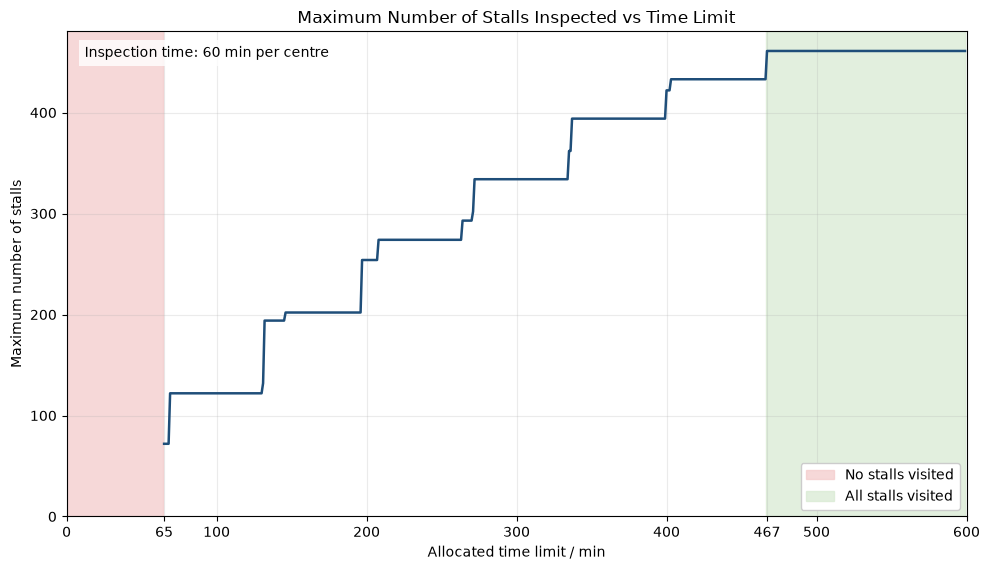

In [20]:
plot_and_save_num_stalls(
    df=results_across_time_limits_df,
    file_path=os.path.join(RESULTS_PATH, f"extension_2_num_stalls_inspection_{INSPECTION_TIME_PER_CENTRE}"),
    total_num_stalls=total_num_stalls
)

#### Total Time Spent vs Time Limit

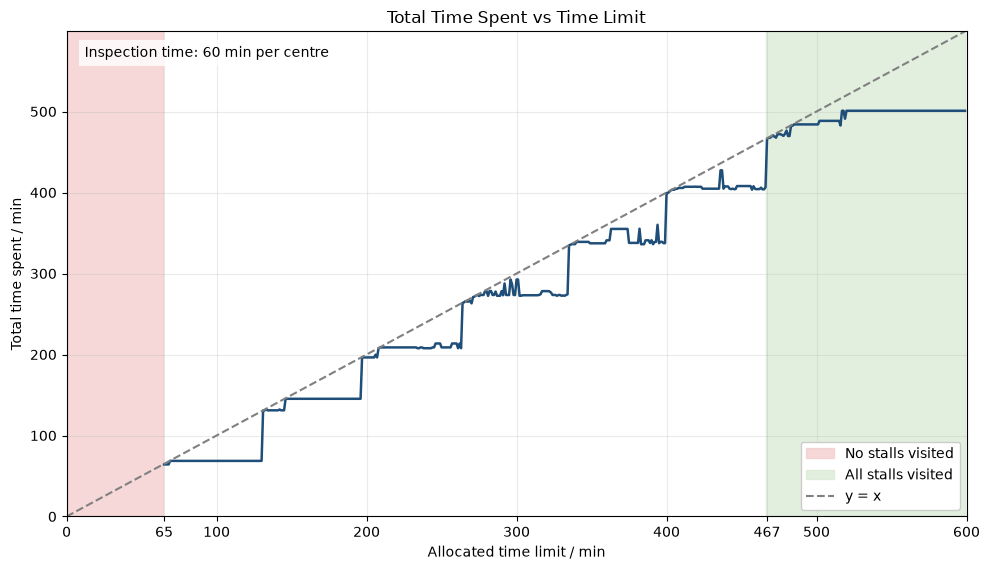

In [21]:
plot_and_save_time_limit(
    df=results_across_time_limits_df,
    file_path=os.path.join(RESULTS_PATH, f"extension_2_time_spent_inspection_{INSPECTION_TIME_PER_CENTRE}"),
    total_num_stalls=total_num_stalls
)